# Trực quan hóa tập dữ liệu về bệnh tiểu đường.

## 1. Mô tả về dữ liệu:

#### Mô tả vấn đề
Bệnh tiểu đường là một trong những bệnh mạn tính phổ biến và nguy hiểm, đặc biệt trong nhóm người có yếu tố nguy cơ như béo phì, tuổi cao, hoặc có tiền sử gia đình.  
Bộ dữ liệu **Pima Indians Diabetes** được thu thập từ phụ nữ Pima (Arizona, Mỹ) ≥ 21 tuổi, nhằm mục tiêu phân tích các yếu tố sức khỏe liên quan đến khả năng mắc bệnh tiểu đường.  

#### Thông tin cơ bản về dữ liệu
- **Số mẫu**: 768  
- **Số thuộc tính**: 8 đặc trưng + 1 biến mục tiêu  
- **Biến mục tiêu**: `Outcome` (0 = không tiểu đường, 1 = có tiểu đường)

#### Ý nghĩa các cột:
- Pregnancies:	
    - Số lần mang thai (kể cả những lần sảy thai hoặc thai chết lưu).
    - Số nguyên (≥0)

- Glucose:
    - Nồng độ glucose trong huyết tương sau khi xét nghiệm miệng dung nạp glucose trong 2 giờ.
    - mg/dL
    - Giá trị 0 là bất thường và thường được coi là giá trị thiếu.

- BloodPressure:
    - Huyết áp tâm trương (huyết áp dưới) tính bằng mmHg.
    - mmHg	
    - Giá trị 0 là bất thường và thường được coi là giá trị thiếu.

- SkinThickness:	
    - Độ dày nếp gấp da cơ tam đầu.	
    - mm	
    - Được sử dụng để ước tính tỷ lệ mỡ cơ thể. Giá trị 0 là bất thường.
- Insulin:
    - Nồng độ insulin trong huyết thanh sau 2 giờ.	
    - mu U/ml	Giá trị 0 là bất thường và thường được coi là giá trị thiếu.
- BMI:	
    - Chỉ số khối cơ thể (Body Mass Index).	
    - kg/m2
    - Được tính bằng cân nặng chia cho bình phương chiều cao. Giá trị 0 là bất thường.
- DiabetesPedigreeFunction:	
    - Hàm phả hệ bệnh tiểu đường.	
    - Số thực (≥0)	
    - Đo lường nguy cơ di truyền mắc bệnh tiểu đường dựa trên tiền sử gia đình.
- Age:	
    - Tuổi của bệnh nhân.	
    - Số nguyên (năm)	
- Outcome:
    - Biến mục tiêu (biến kết quả).	
    - {0,1}	1: Mắc bệnh tiểu đường. 0: Không mắc bệnh tiểu đường.

## 2. Import thư viện và kiểm tra dữ liệu

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler

- Thực hiện việc **nạp dữ liệu gốc** từ file `diabetes.csv` vào Python bằng thư viện `pandas`.  
- Do file CSV chứa tiêu đề cột (header), ta không cần **gán tên cột**
- Kết quả: dữ liệu được lưu vào một **DataFrame** có cấu trúc rõ ràng.

In [2]:
# Đọc dữ liệu từ file CSV
data = pd.read_csv("data/diabetes.csv")

In [4]:
# Kiểm tra dữ liệu
# Thông tin dữ liệu
data.info()
# Thống kê mô tả
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [6]:
# Tên các cột
data.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [7]:
# Kích thước dữ liệu
data.shape

(768, 9)

In [8]:
# Hiển thị 5 dòng đầu để kiểm tra
print("5 dòng đầu của dữ liệu:")
print(data.head())

5 dòng đầu của dữ liệu:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [9]:
print("5 dòng cuối của dữ liệu:")
print(data.tail())

5 dòng cuối của dữ liệu:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.1   
767            1       93             70             31        0  30.4   

     DiabetesPedigreeFunction  Age  Outcome  
763                     0.171   63        0  
764                     0.340   27        0  
765                     0.245   30        0  
766                     0.349   47        1  
767                     0.315   23        0  


- Các thống kê mô tả chính và ý nghĩa:
    + count: số lượng mẫu dữ liệu (ở đây tất cả cột = 768).
    + mean: giá trị trung bình.
    + std: độ lệch chuẩn → mức độ phân tán quanh trung bình.
    + min, max: giá trị nhỏ nhất và lớn nhất.
    + 25%, 50%, 75% (quartiles): các mốc phân vị → dùng để đánh giá sự phân phối dữ liệu.

- Chỉ số đo lường sự biến động (Dispersion):
    + std (độ lệch chuẩn):
        + Glucose: 32 → biến thiên khá lớn, thể hiện sự khác biệt giữa người khỏe mạnh và người có nguy cơ cao.
        + Insulin: 115, lớn hơn cả mean (~80) → chứng tỏ dữ liệu rất phân tán và nhiều ngoại lệ.
        + BMI: 7.88 → tương đối ổn định, dao động vừa phải.
        + Age: 11.8 → đa dạng độ tuổi, từ 21 đến 81 tuổi.
- Khoảng (range = max - min):
    + Pregnancies: 0–17, cho thấy có vài trường hợp đặc biệt mang thai rất nhiều lần.
    + Insulin: 0–846, cực kỳ phân tán → cần chuẩn hóa hoặc log-transform khi phân tích.
    + SkinThickness: 0–99, cũng có nhiều giá trị bất hợp lý.

In [10]:
# Kiểm tra giá trị thiếu
data.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [11]:
# Kiểm tra giá trị 0 trong các cột
(data==0).sum()

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

- **Nhận xét:** Không có giá trị nào Null

In [12]:
# Kiểm tra giá trị trùng lặp
data.duplicated().sum()

0

- **Nhận xét về dữ liệu có giá trị 0:**  
   1. Pregnancies (111 giá trị 0):
      + 0 lần mang thai là hợp lý (có những phụ nữ chưa từng mang thai).
      + Không cần xử lý coi là missing.
   2. Glucose (5 giá trị 0):
      + Về mặt y khoa, glucose máu không thể = 0.
      + Đây là giá trị bất thường → coi là dữ liệu thiếu.
   3. BloodPressure (35 giá trị 0):
      + Huyết áp tâm trương không thể = 0.
      + Các giá trị này là missing values cần xử lý
   4. SkinThickness (227 giá trị 0):
      + 0 mm nếp gấp da là không hợp lý.
      + Đây là một biến có nhiều thiếu dữ liệu (≈ 30% dữ liệu).
   5. Insulin (374 giá trị 0):
      + 0 µU/mL insulin là không thực tế.
      + Biến này có nhiều dữ liệu thiếu nhất (≈ 49%).
   6. BMI (11 giá trị 0):
      + BMI = 0 là bất hợp lý.
      + Một số ít dữ liệu cần xử lý missing.
   7. DiabetesPedigreeFunction (0 giá trị 0):
      + Không có giá trị 0, dữ liệu đầy đủ.
   8. Age (0 giá trị 0):
      + Không có giá trị 0, dữ liệu đầy đủ.
   9. Outcome (500 giá trị 0):
      + Đây là biến nhãn (class):
         + 0 = không mắc tiểu đường (500 mẫu).
         + 1 = mắc tiểu đường (268 mẫu).
      + Đây không phải dữ liệu thiếu mà là nhãn hợp lệ.

## 3. Xử lý dữ liệu

#### Xử lý dữ liệu bị thiếu
- Dữ liệu này không có giá trị nào Null, chỉ có giá trị bằng 0, nên ta thay giá trị 0 bằng NaN để xử lý

In [13]:

# Thay thế giá trị 0 bằng NaN để xử lý
for column in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    data[column] = data[column].replace(0, np.nan)

# Sử dụng SimpleImputer để điền giá trị thiếu bằng trung bình
imputer = SimpleImputer(strategy='mean') # Có thể thay 'mean' bằng 'median' hoặc 'most_frequent' tùy theo yêu cầu
data[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']] = imputer.fit_transform(data[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']])

# Kiểm tra lại số lượng giá trị thiếu
print("Số lượng giá trị thiếu sau khi xử lý:")
print(data.isnull().sum())

Số lượng giá trị thiếu sau khi xử lý:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


- Việc thay thế bằng trung bình giúp duy trì tính đại diện của dữ liệu mà không làm mất thông tin quan trọng.
    - SimpleImputer với chiến lược mean thay thế các giá trị thiếu (bao gồm cả null và NaN) bằng trung bình của cột, giữ nguyên ý nghĩa thống kê.
    - Sau khi xử lý, tất cả giá trị thiếu sẽ được điền, đảm bảo dữ liệu không còn khoảng trống.

#### Xử lý chuẩn hóa dữ liệu
- Giới thiệu MinMaxScaler (sklearn.preprocessing)
- **MinMaxScaler** là một công cụ trong thư viện **Scikit-learn** dùng để **chuẩn hóa dữ liệu (feature scaling)**.  
- Nguyên lý hoạt động: đưa toàn bộ giá trị của một biến về trong **khoảng [0, 1]** (hoặc một khoảng tùy chọn do người dùng định nghĩa). 
Công thức biến đổi:
$$
X' = \frac{X - X_{min}}{X_{max} - X_{min}}
$$
Trong đó:  
- \(X\) là giá trị gốc,  
- \(X_{min}\) là giá trị nhỏ nhất của cột,  
- \(X_{max}\) là giá trị lớn nhất của cột,  
- \(X'\) là giá trị đã được scale (nằm trong [0,1]). 

In [14]:
# Chuẩn hóa dữ liệu bằng MinMaxScaler

# Kiểm tra phạm vi giá trị của các cột
print("\nPhạm vi giá trị của các cột:")
print(data.describe())

scaler = MinMaxScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(data.drop('Outcome', axis=1)), columns=data.drop('Outcome', axis=1).columns)
data_scaled['Outcome'] = data['Outcome']

# Hiển thị 5 dòng đầu của dữ liệu đã chuẩn hóa
print("\n5 dòng đầu của dữ liệu đã chuẩn hóa:")
print(data_scaled.head())


Phạm vi giá trị của các cột:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  121.686763      72.405184      29.153420  155.548223   
std       3.369578   30.435949      12.096346       8.790942   85.021108   
min       0.000000   44.000000      24.000000       7.000000   14.000000   
25%       1.000000   99.750000      64.000000      25.000000  121.500000   
50%       3.000000  117.000000      72.202592      29.153420  155.548223   
75%       6.000000  140.250000      80.000000      32.000000  155.548223   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    32.457464                  0.471876   33.240885    0.348958  
std      6.875151                  0.331329   11.760232    0.476951  
min  

- describe() kiểm tra phạm vi giá trị (min, max) để đánh giá cần chuẩn hóa không. Ví dụ, Age và Pregnancies có thể có giá trị lớn hơn các cột khác.
- MinMaxScaler chuẩn hóa dữ liệu về khoảng [0, 1], giúp các thuộc tính có cùng thang đo, đặc biệt quan trọng cho mô hình hóa sau này.
- Dữ liệu chuẩn hóa được lưu vào data_scaled. Có thể gán data = data_scaled nếu muốn sử dụng ngay.

In [15]:
# Hiển thị thông tin cơ bản sau khi xử lý
print("\nThông tin cơ bản về dữ liệu sau khi xử lý:")
print(data_scaled.info())

# Phân bố lớp sau khi xử lý
print("\nPhân bố biến lớp (Outcome) sau khi xử lý:")
print(data_scaled['Outcome'].value_counts())


Thông tin cơ bản về dữ liệu sau khi xử lý:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    float64
 1   Glucose                   768 non-null    float64
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    float64
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    float64
 8   Outcome                   768 non-null    int64  
dtypes: float64(8), int64(1)
memory usage: 54.1 KB
None

Phân bố biến lớp (Outcome) sau khi xử lý:
Outcome
0    500
1    268
Name: count, dtype: int64


In [16]:
data_scaled.describe

<bound method NDFrame.describe of      Pregnancies   Glucose  BloodPressure  SkinThickness   Insulin       BMI  \
0       0.352941  0.670968       0.489796       0.304348  0.170130  0.314928   
1       0.058824  0.264516       0.428571       0.239130  0.170130  0.171779   
2       0.470588  0.896774       0.408163       0.240798  0.170130  0.104294   
3       0.058824  0.290323       0.428571       0.173913  0.096154  0.202454   
4       0.000000  0.600000       0.163265       0.304348  0.185096  0.509202   
..           ...       ...            ...            ...       ...       ...   
763     0.588235  0.367742       0.530612       0.445652  0.199519  0.300613   
764     0.117647  0.503226       0.469388       0.217391  0.170130  0.380368   
765     0.294118  0.496774       0.489796       0.173913  0.117788  0.163599   
766     0.058824  0.529032       0.367347       0.240798  0.170130  0.243354   
767     0.058824  0.316129       0.469388       0.260870  0.170130  0.249489   

     

## 4. Trực quan hóa dữ liệu

#### Import thư viện

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Sự phân bố các biến

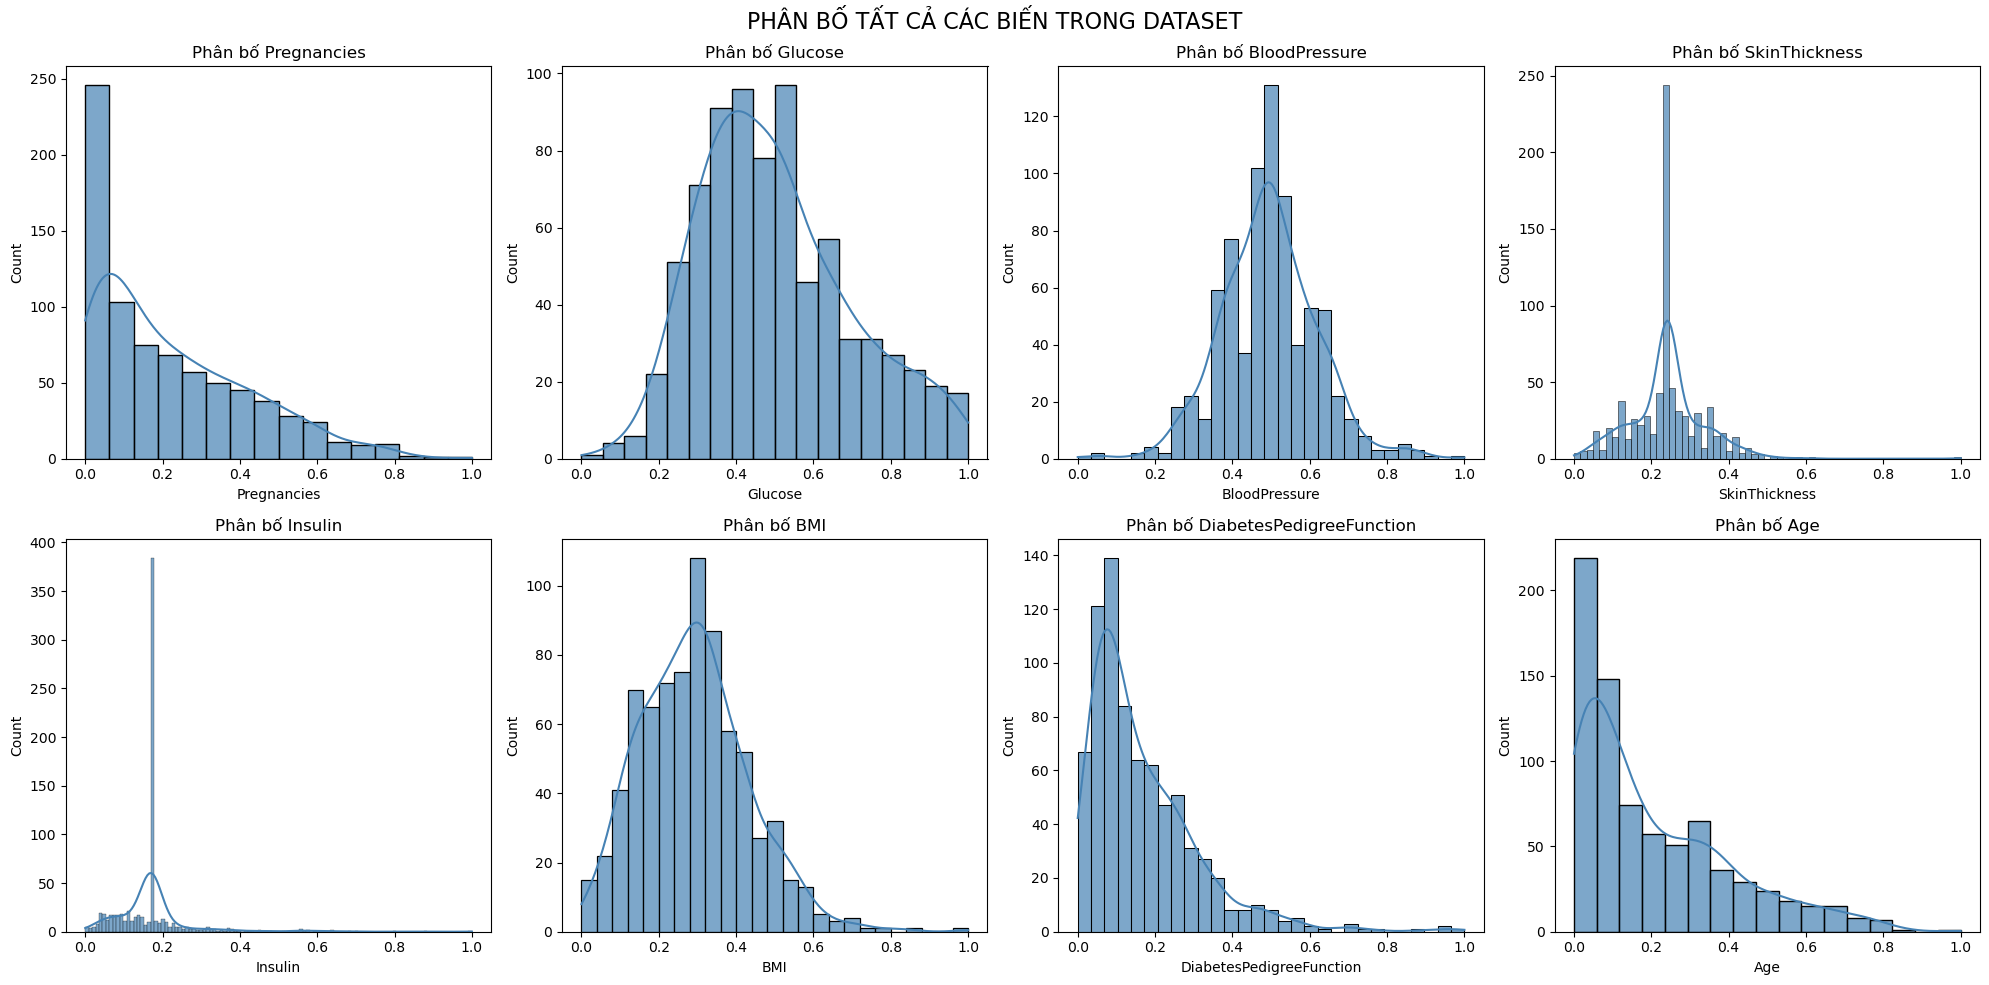

In [23]:
all_vars = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 
            'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

# Tạo subplot 2x4 cho 8 biến
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for i, col in enumerate(all_vars):
    row = i // 4  # 0 hoặc 1
    col_idx = i % 4  # 0, 1, 2, 3
    sns.histplot(data=data_scaled, x=col, kde=True, ax=axes[row, col_idx], color='steelblue', alpha=0.7)
    axes[row, col_idx].set_title(f'Phân bố {col}')

plt.suptitle('PHÂN BỐ TẤT CẢ CÁC BIẾN TRONG DATASET', fontsize=16)
plt.tight_layout()
plt.show()

**Nhận xét**

**1. Pregnancies**
- Phân bố **lệch phải mạnh**, phần lớn giá trị nhỏ (về phía 0).  
- Chỉ một số ít người có giá trị cao (về phía 1).  
→ **Đa số phụ nữ ít mang thai hơn**, phản ánh đặc trưng dân số trong mẫu khảo sát.  

**2. Glucose**
- Phân bố **gần chuẩn**, tập trung quanh vùng giữa (0.4–0.6).  
- Có một số giá trị cao (gần 1) → nhóm có khả năng mắc tiểu đường hoặc nguy cơ cao.  
→ Đây là **biến có khả năng phân biệt rõ nhất giữa nhóm bệnh và không bệnh**.  

**3. BloodPressure**
- Dạng **tương đối cân đối**, tập trung quanh vùng giữa (0.4–0.6).  
- Ít giá trị cực đoan → dữ liệu huyết áp ổn định, đáng tin cậy.  

**4. SkinThickness**
- Phân bố **lệch phải rõ rệt**, nhiều giá trị thấp (0.1–0.3) và đỉnh nổi bật quanh 0.25.  
→ Có thể chứa **giá trị thay thế trung bình hoặc lỗi nhập liệu**, nên cần xem xét thêm khi tiền xử lý.  

**5. Insulin**
- Phân bố **rất lệch phải**, đỉnh nhọn ở khoảng 0.2, rải rác giá trị cao gần 1.  
→ Cho thấy **nhiều giá trị ngoại lai (outlier)**, biến này cần được **log-transform** hoặc giới hạn ngưỡng trên. 

**6. BMI**
- Phân bố **gần chuẩn**, hơi lệch phải nhẹ, tập trung quanh 0.3–0.5.  
→ Phản ánh nhóm người **thừa cân hoặc béo phì chiếm đa số**, phù hợp với dữ liệu bệnh tiểu đường.  

**7. DiabetesPedigreeFunction**
- Phân bố **lệch phải**, phần lớn giá trị nhỏ (<0.3), chỉ vài giá trị cao (>0.8).  
→ Biểu thị **yếu tố di truyền** — có ít cá thể có nguy cơ di truyền cao.  

**8. Age**
- Phân bố **lệch phải rõ rệt**, tập trung nhiều ở nhóm giá trị thấp (0.2–0.3).  
→ Mẫu dữ liệu chủ yếu là **người trẻ và trung niên**, ít người cao tuổi.  

**Tổng kết**
- Sau chuẩn hóa, **phân bố giữa các biến dễ so sánh hơn**, nhưng **độ lệch phải vẫn còn**.  
- Các biến `Glucose, BMI, Age, Pregnancies` cho thấy xu hướng rõ rệt liên quan đến nguy cơ tiểu đường.  
- Các biến như `Insulin` và `SkinThickness` cần được **kiểm tra hoặc biến đổi** để giảm ảnh hưởng của outlier trước khi mô hình hóa.


#### Boxplot của từng biến, nhóm theo Outcome

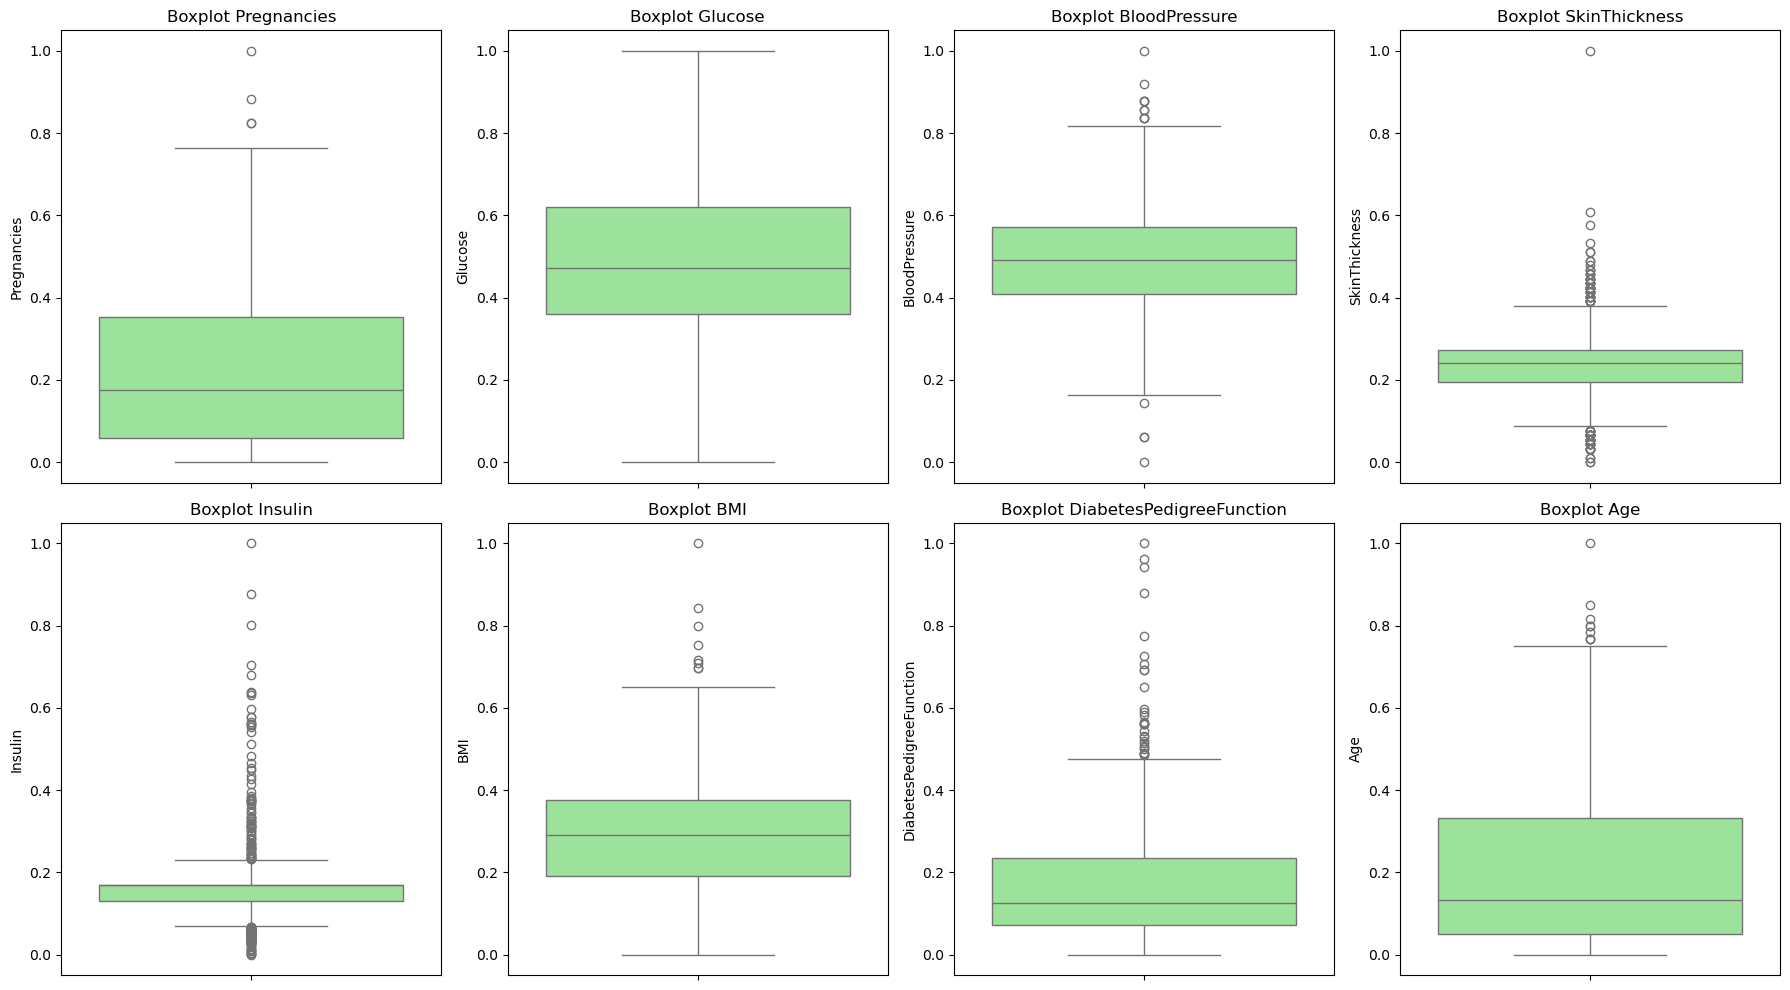

In [24]:
# Boxplot cho các biến chính
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
for i, col in enumerate(all_vars):
    ax = axes[i//4, i%4]
    sns.boxplot(data=data_scaled, y=col, ax=ax, color='lightgreen')
    ax.set_title(f'Boxplot {col}')
plt.tight_layout()
plt.show()

**1. Pregnancies**
- Trung vị thấp (khoảng 0.15–0.2) và râu trên dài → dữ liệu **lệch phải**.  
- Một số outlier ở phần giá trị cao (gần 1).  
→ Cho thấy phần lớn phụ nữ có ít lần mang thai, chỉ vài người có số lần cao bất thường.  

**2. Glucose**
- Trung vị quanh 0.5, hộp gọn, râu trên và dưới cân đối → **phân bố ổn định, gần chuẩn**.  
- Rất ít outlier.  
→ Dữ liệu Glucose sạch, phù hợp để mô hình dự đoán.  

**3. BloodPressure**
- Trung vị khoảng 0.45–0.5, râu trên hơi dài → **phân bố khá cân đối**, chỉ có vài outlier nhỏ.  
→ Biến ổn định, thể hiện giá trị huyết áp hợp lý về mặt sinh học.  

**4. SkinThickness**
- Trung vị khoảng 0.25, hộp hẹp, râu trên dài và có nhiều điểm ngoại lai.  
→ Biến này **có nhiều giá trị bất thường hoặc bị thay thế bằng trung bình**; cần kiểm tra lại dữ liệu gốc.  

**5. Insulin**
- Trung vị thấp (~0.15), rất nhiều outlier kéo dài đến 1.0 → **biến có phân tán rộng và nhiều ngoại lai rõ rệt**.  
→ Nên xem xét **log-transform hoặc loại bỏ outlier cực đoan** trước khi modeling.  

**6. BMI**
- Trung vị khoảng 0.3, hộp tương đối gọn, chỉ vài outlier cao.  
→ Dữ liệu khá ổn định, **ít nhiễu**, phản ánh tình trạng thừa cân phổ biến trong mẫu khảo sát.  

**7. DiabetesPedigreeFunction**
- Trung vị thấp (~0.15), râu trên dài, nhiều outlier phía trên 0.6–1.0.  
→ Một số cá thể có **yếu tố di truyền mạnh**, nhưng phần lớn có mức nguy cơ thấp.  

**8. Age**
- Trung vị thấp (~0.2), râu trên dài với một vài outlier cao gần 1.0.  
→ Mẫu chủ yếu là người trẻ, nhưng có một số ít người cao tuổi.  

**Tổng kết**
- `Insulin` và `SkinThickness` là hai biến có `nhiều ngoại lai nhất`, cần xử lý kỹ trước khi đưa vào mô hình.  
- `Glucose, BloodPressure, BMI` là các biến ổn định, phân bố hợp lý, đáng tin cậy cho phân tích.  
- `Pregnancies, Age, DPF` thể hiện xu hướng lệch phải tự nhiên, phản ánh đúng đặc trưng dân số khảo sát.

#### Ma trận tương quan giữa các biến

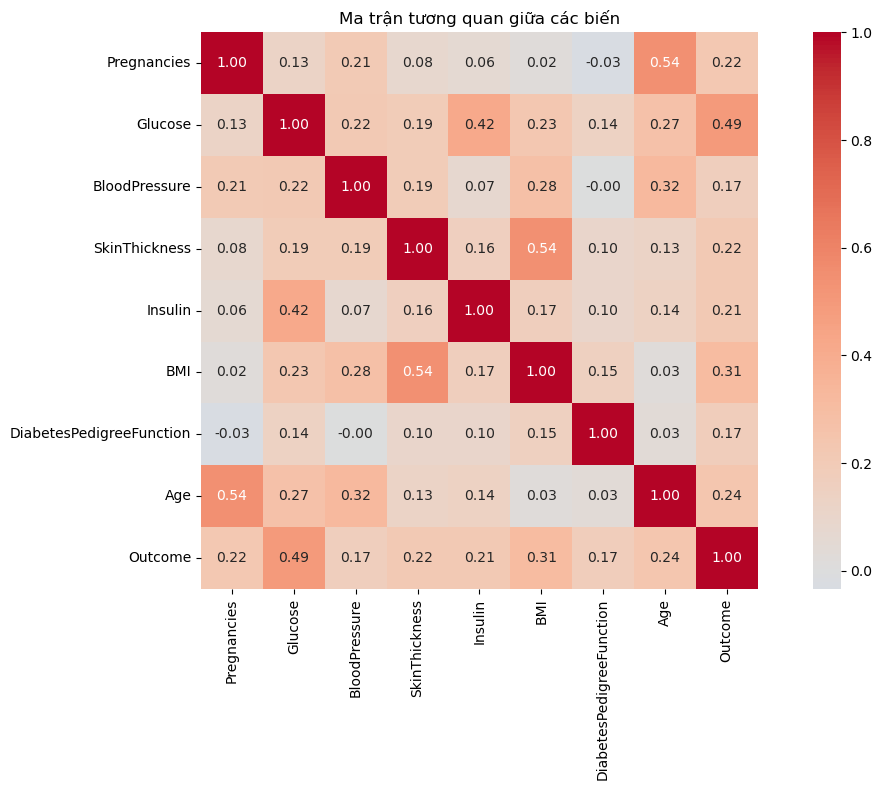

In [25]:
plt.figure(figsize=(12, 8))
correlation_matrix = data_scaled.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.2f')
plt.title('Ma trận tương quan giữa các biến')
plt.tight_layout()
plt.show()

**1. Các cặp biến có tương quan cao**
- *BMI ↔ SkinThickness (0.54):* Tương quan mạnh nhất giữa các biến độc lập.  
  → Người có lớp da dày thường có chỉ số BMI cao, phản ánh lượng mỡ cơ thể.  
- *Pregnancies ↔ Age (0.54):* Tương quan thuận rõ rệt, cho thấy **tuổi càng cao thì số lần mang thai càng nhiều**.  
- *Glucose ↔ Insulin (0.42):* Tương quan trung bình, hợp lý về mặt sinh học vì **nồng độ glucose tăng thường kéo theo tăng insulin**.  

**2. Mối liên hệ giữa các biến và biến mục tiêu `Outcome`**
- *Glucose (0.49):* Tương quan mạnh nhất với `Outcome`.  
  → Đây là **yếu tố chính xác định nguy cơ tiểu đường**, nồng độ glucose cao tương ứng với khả năng mắc bệnh cao.  
- *BMI (0.31):* Có tương quan vừa → **người thừa cân hoặc béo phì** dễ mắc tiểu đường hơn.  
- *Age (0.24)* và *Pregnancies (0.22):* Tương quan yếu nhưng **vẫn đáng kể**, phản ánh **tuổi và số lần mang thai** cũng là yếu tố nguy cơ.  
- Các biến còn lại như *BloodPressure, Insulin, SkinThickness, DiabetesPedigreeFunction* có tương quan yếu (< 0.22) nhưng vẫn có thể hữu ích khi kết hợp trong mô hình.  

**3. Nhận xét về mức độ độc lập của dữ liệu**
- Không có cặp biến nào có hệ số tương quan > 0.8 → **không xuất hiện đa cộng tuyến nghiêm trọng**.  
- Dữ liệu **đa dạng và không bị trùng lặp thông tin**, thuận lợi cho các thuật toán tuyến tính hoặc logistic regression.

**Tổng kết**
- `Glucose` là biến có ảnh hưởng mạnh nhất đến khả năng mắc tiểu đường.  
- `BMI, Age, Pregnancies` là các yếu tố phụ nhưng vẫn thể hiện xu hướng tương quan tích cực với `Outcome`.  
- `BMI–SkinThickness` và `Pregnancies–Age` có mối quan hệ tương đối cao giữa các biến độc lập, cần chú ý nếu sử dụng mô hình tuyến tính.  
**Tổng thể**: ma trận tương quan cho thấy bộ dữ liệu cân bằng, không có vấn đề nghiêm trọng về tương quan nội tại.

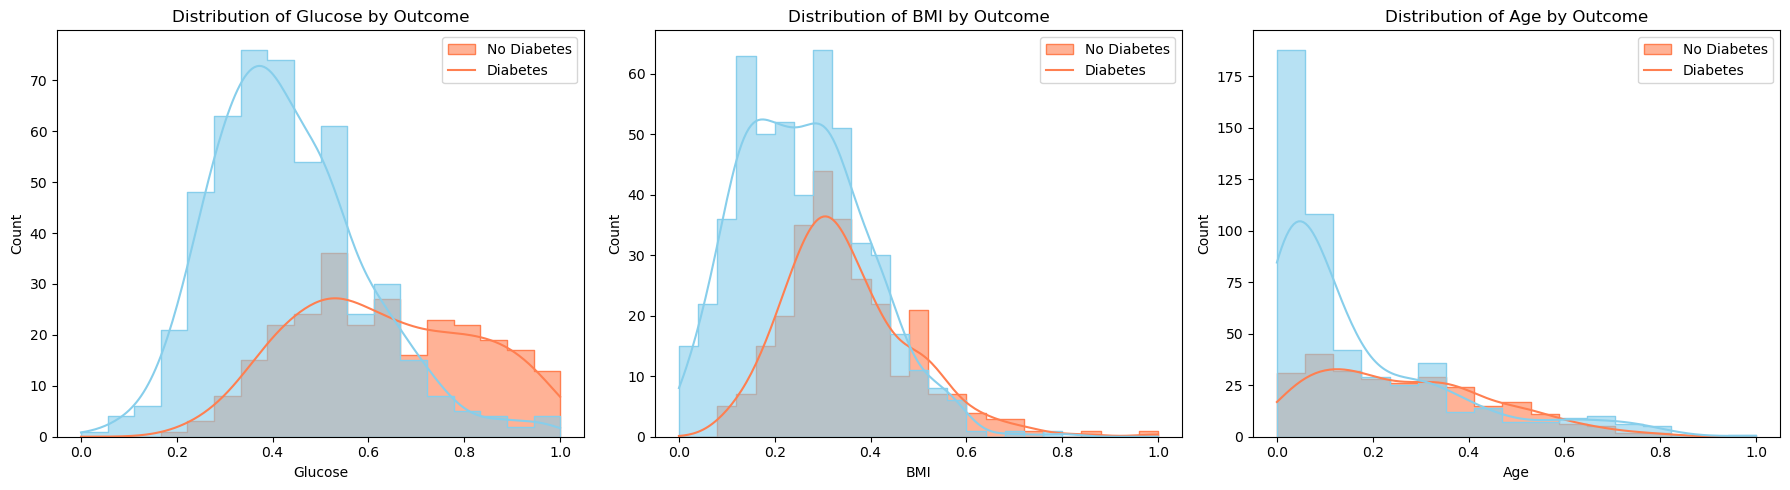

In [22]:
key_features = ['Glucose', 'BMI', 'Age']

# Vẽ histogram/kde so sánh
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(key_features):
    # Histogram với KDE
    sns.histplot(data=data_scaled, x=feature, hue='Outcome', 
                 kde=True, element='step', 
                 palette={0: 'skyblue', 1: 'coral'},
                 alpha=0.6, ax=axes[i])
    
    axes[i].set_title(f'Distribution of {feature} by Outcome')
    axes[i].legend(['No Diabetes', 'Diabetes'])

plt.tight_layout()
plt.show()

**1. Glucose**
- Nhóm **Diabetes (màu cam)** có phân bố dịch sang phải (giá trị cao hơn), trong khi nhóm **No Diabetes (màu xanh)** tập trung ở vùng thấp hơn (0.3–0.6).  
- Điều này cho thấy **người mắc bệnh tiểu đường có nồng độ Glucose cao hơn rõ rệt**.  
→ Đây là **biến phân biệt mạnh nhất giữa hai nhóm**, tương ứng với kết quả từ ma trận tương quan (r = 0.49).  

**2. BMI**
- Nhóm **Diabetes** có phân bố hơi lệch sang phải, tập trung ở vùng **BMI cao hơn (0.3–0.6)**.  
- Nhóm **No Diabetes** chủ yếu ở vùng **BMI thấp hơn (0.2–0.4)**.  
→ Người **thừa cân hoặc béo phì** có xu hướng mắc tiểu đường cao hơn.  
→ Mức độ khác biệt không mạnh như Glucose nhưng vẫn thể hiện **tác động rõ ràng**.  

**3. Age**
- Cả hai nhóm đều lệch phải (phần lớn người trẻ), nhưng nhóm **Diabetes** có phân bố trải rộng hơn và đỉnh thấp hơn → **tuổi trung bình cao hơn**.  
→ Nguy cơ mắc bệnh **tăng theo tuổi**, đúng với xu hướng sinh học thông thường.  

**Tổng kết**
- Ba biến `Glucose, BMI, Age` đều thể hiện **sự khác biệt rõ ràng giữa hai nhóm Outcome**.  
- `Glucose` là yếu tố quan trọng nhất, tiếp theo là `BMI` và `Age`.  
- Kết quả này củng cố các quan sát trước từ heatmap và boxplot, chứng minh rằng các biến này **có giá trị cao trong việc dự đoán nguy cơ tiểu đường**.

## 5. Kết luận

- Dữ liệu gồm 8 biến độc lập và 1 biến mục tiêu (`Outcome`), đã được làm sạch và chuẩn hóa.  
- Phần lớn biến **lệch phải**, trong đó `Insulin` và `SkinThickness` có nhiều outlier.  
- `Glucose, BMI, Age, Pregnancies` là các biến có **liên hệ rõ rệt với Outcome**, đặc biệt `Glucose` thể hiện sự khác biệt mạnh nhất.  
- Ma trận tương quan cho thấy **không có đa cộng tuyến nghiêm trọng**, các biến độc lập tương đối tốt.  
- Nhóm mắc tiểu đường có `Glucose, BMI, Age` cao hơn nhóm không mắc → dữ liệu phản ánh đúng xu hướng bệnh lý.